# Scene 63: RAW → polarimetric environment map

Use the **PEnvMap processing (Python 3.13)** kernel. RAW data is external: this
repository does not copy or bundle the ~1.16 GB capture. Download the full-Stokes
distribution and set `DATASET_ROOT` to its `full_stokes` folder below, or set the
`PENVMAP_DATASET` environment variable. The expected input is `raw/63` with
`envmap/hdr`, `color/hdr` and the sibling `calibration` directory.

Scene 63 has Basler full-Stokes captures (S0–S3). It contains no Sun/Floor shots;
the same pipeline skips those optional stages. Scene-specific WB and vignetting
map2 are selected using `processing.yaml`.


In [1]:
from pathlib import Path
import os
import sys
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "main.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATASET_ROOT = Path(os.environ.get("PENVMAP_DATASET", str(ROOT / "data/full_stokes"))).expanduser().resolve()
OUTPUT = ROOT / "example/output/63"
CHANNEL = "G"   # B, G or R: channel used for normalized Stokes panels
DISPLAY_LIMIT = 1.0  # shared RdBu range [-limit, +limit]

assert sys.version_info[:2] == (3, 13), "Select the processing Python 3.13 kernel."
RAW_SCENE = DATASET_ROOT / "raw/63"
if not RAW_SCENE.is_dir():
    raise FileNotFoundError("Set DATASET_ROOT to the downloaded full_stokes distribution; expected raw/63.")
print("Input: full_stokes/raw/63 · Basler · full Stokes")


Input: full_stokes/raw/63 · Basler · full Stokes


## Processing options

This is the same `main.py` entry point used outside the notebook. Change
`--width`, `--stokes-repr`, `--rotation-model` or your processing YAML if needed.
The output directory is separate from the external RAW data.


In [2]:
from pemap.io.arguments import parse_scene_args
options = parse_scene_args([
    str(RAW_SCENE), "--camera", "basler", "--output-root", str(OUTPUT),
    "--width", "2048", "--mode", "full", "--minimal-analysis",
], default_config=ROOT / "processing.yaml")
print(f"Panorama: {options.width} × {options.height} · {options.stokes_repr_mode} · {options.rotation_model}")


Panorama: 2048 × 1024 · s2l2 · min_rot


## Run RAW → result

RAW bracket fusion → sensor Stokes/vignetting → colour selection → view masks
and rotation refinement → per-ray coordinate conversion → warp/multiband →
WB/CCM → optional Sun/Floor → final EXRs. Detailed stdout is retained in
`processing_log` for local inspection; only a short summary is shown here.


In [3]:
import contextlib
import io
import json
from main import merge_penvmap
processing_log = io.StringIO()
with contextlib.redirect_stdout(processing_log), contextlib.redirect_stderr(processing_log):
    result = merge_penvmap(options)
record = json.loads((OUTPUT / "result/run.json").read_text(encoding="utf-8"))
print("Completed scene 63: thetaphi.exr, duff.exr and s2l2.exr")
print("Measured S3:", record["polarimetric"]["S3_measured"],
      "| Uncovered pixels:", record["coverage"]["remaining_missing_pixels"])


Completed scene 63: thetaphi.exr, duff.exr and s2l2.exr
Measured S3: True | Uncovered pixels: 0


## View the result

S0 is a display-only exposure-adjusted sRGB image. **S1n, S2n and S3n are
Si/S0 from the linear data**, before exposure/gamma. The signed panels use
polanalyser's RdBu colormap and a fixed common range. They show the selected
B/G/R channel (G by default), not an unspecified RGB average. Dark/unobserved
pixels are grey. Change `CHANNEL` or `DISPLAY_LIMIT` and rerun this cell to inspect
other channels or weaker polarization. The EXRs are not modified by visualization.


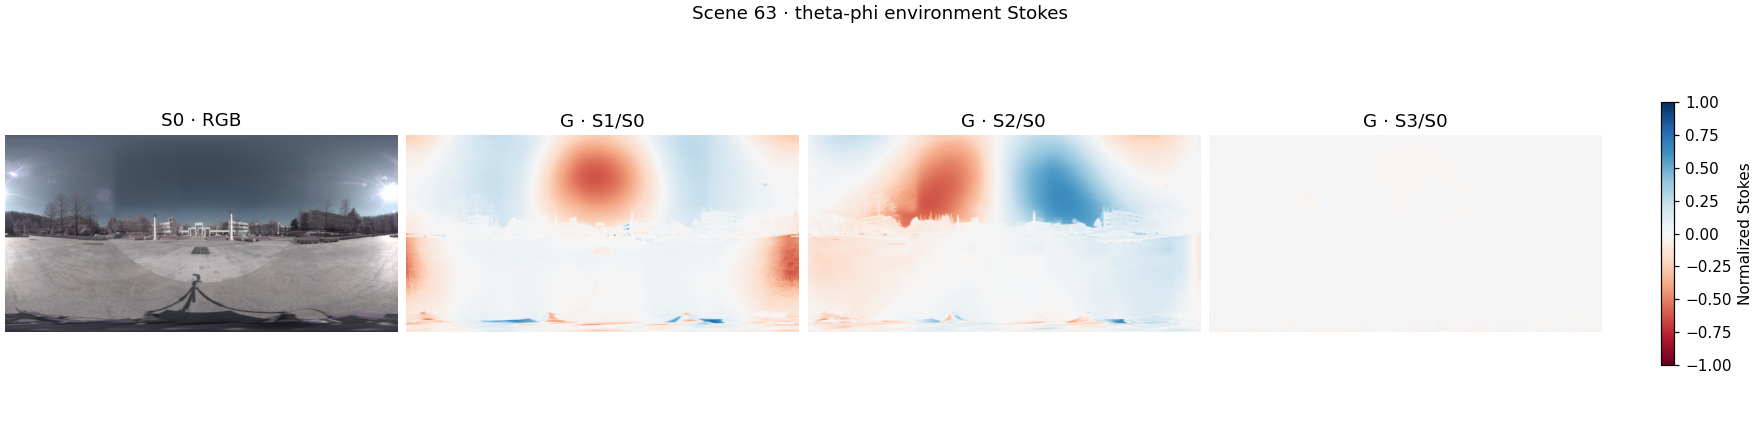

In [4]:
import matplotlib.pyplot as plt
from example.visualize import read_stokes, plot_stokes
stokes = read_stokes(OUTPUT / "result/thetaphi.exr")
figure = plot_stokes(stokes, channel=CHANNEL, limit=DISPLAY_LIMIT,
                      title="Scene 63 · theta-phi environment Stokes")
display(figure)
plt.close(figure)


Use `example/output/63/result/duff.exr` as the input to notebook 02.
`thetaphi.exr` is used here for visualization; the custom renderer expects the
**Duff-basis RGB S0–S3 EXR**, not the 12-coefficient `s2l2.exr`.
